### Importing libraries

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


### Loading the dataset

In [99]:
df = pd.read_csv("../data/powerconsumption.csv")

## Task 1: Data Quality Inspection and Cleaning

In [100]:
df.shape

(52416, 9)

The dataset has 52,416 records and 9 fields.

In [101]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [102]:
df.columns.tolist()

['Datetime',
 'Temperature',
 'Humidity',
 'WindSpeed',
 'GeneralDiffuseFlows',
 'DiffuseFlows',
 'PowerConsumption_Zone1',
 'PowerConsumption_Zone2',
 'PowerConsumption_Zone3']

In [103]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


Datetime is stored as a string. It should be converted to datetime64[ns].

### Handling missing values

In [104]:
df.isnull().sum()

Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

No missing values were detected in the dataset.

### Handling duplicates

In [105]:
df.duplicated().sum()

np.int64(0)

No duplicates were identified in the dataset.

### Converting the datetime field.

In [ ]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Datetime                52416 non-null  datetime64[us]
 1   Temperature             52416 non-null  float64       
 2   Humidity                52416 non-null  float64       
 3   WindSpeed               52416 non-null  float64       
 4   GeneralDiffuseFlows     52416 non-null  float64       
 5   DiffuseFlows            52416 non-null  float64       
 6   PowerConsumption_Zone1  52416 non-null  float64       
 7   PowerConsumption_Zone2  52416 non-null  float64       
 8   PowerConsumption_Zone3  52416 non-null  float64       
dtypes: datetime64[us](1), float64(8)
memory usage: 3.6 MB


In [108]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


The datetime column was converted successfully from string to the datetime64[ns] format.

### Inspecting the Date Range

In [109]:
print("Start Date:", df['Datetime'].min())

Start Date: 2017-01-01 00:00:00


In [110]:
print("End Date:",df['Datetime'].max())

End Date: 2017-12-30 23:50:00


The date range is verified to range from 01 January 2017 to 30 December 2017.

### Examining the 10-minute interval consistency.

In [111]:
df = df.sort_values('Datetime')

In [112]:
df['Time_Difference'] = df['Datetime'].diff()

In [113]:
df['Time_Difference'].value_counts().head()

Time_Difference
0 days 00:10:00    52415
Name: count, dtype: int64

This confirms that the time interval in the dataset is 10 minutes.

## Summary of Data Quality Inspection
- The dataset loaded successfully
- The dataset is made up of 52,416 rows and 9 columns.
- No missing values and duplicates were identified.
- The Datetime column was successfully converted from string to the datetime format.
- The dataset period ranges from 01 January 2017 to 30 December 2017.
- The recording intervals are consistent at 10 minutes
- No major data quality issues were detected.

## Task 2: Data Preparation
### Feature Engineering: Extracting year, month, day, hour, day of week, and date columns from the datetime field.

In [114]:
df['Year'] = df['Datetime'].dt.year

In [115]:
df['Month'] = df['Datetime'].dt.month

In [116]:
df['Month_Name'] = df['Datetime'].dt.month_name()

In [117]:
df['Day'] = df['Datetime'].dt.day

In [118]:
df['Hour'] = df['Datetime'].dt.hour

In [119]:
df['Day_of_Week'] = df['Datetime'].dt.day_name()

In [120]:
df['Date'] = df['Datetime'].dt.date

In [121]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Time_Difference,Year,Month,Month_Name,Day,Hour,Day_of_Week,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,NaT,2017,1,January,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0 days 00:10:00,2017,1,January,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0 days 00:10:00,2017,1,January,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0 days 00:10:00,2017,1,January,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0 days 00:10:00,2017,1,January,1,0,Sunday,2017-01-01


The year, month, day, hour, day of week, and date field were successfully extracted from the datetime column.

## Task 3 and 5: Electricity Consumption Analysis with visualizations

In [122]:
df.describe()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Time_Difference,Year,Month,Day,Hour
count,52416,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52415,52416.0,52416.000000,52416.000000,52416.000000
mean,2017-07-01 23:55:00,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218,0 days 00:10:00,2017.0,6.510989,15.678571,11.500000
min,2017-01-01 00:00:00,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070,0 days 00:10:00,2017.0,1.000000,1.000000,0.000000
25%,2017-04-01 23:57:30,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630,0 days 00:10:00,2017.0,4.000000,8.000000,5.750000
50%,2017-07-01 23:55:00,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470,0 days 00:10:00,2017.0,7.000000,16.000000,11.500000
75%,2017-09-30 23:52:30,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420,0 days 00:10:00,2017.0,9.250000,23.000000,17.250000
max,2017-12-30 23:50:00,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360,0 days 00:10:00,2017.0,12.000000,31.000000,23.000000
std,NaN,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099,0 days 00:00:00,0.0,3.440642,8.771822,6.922253


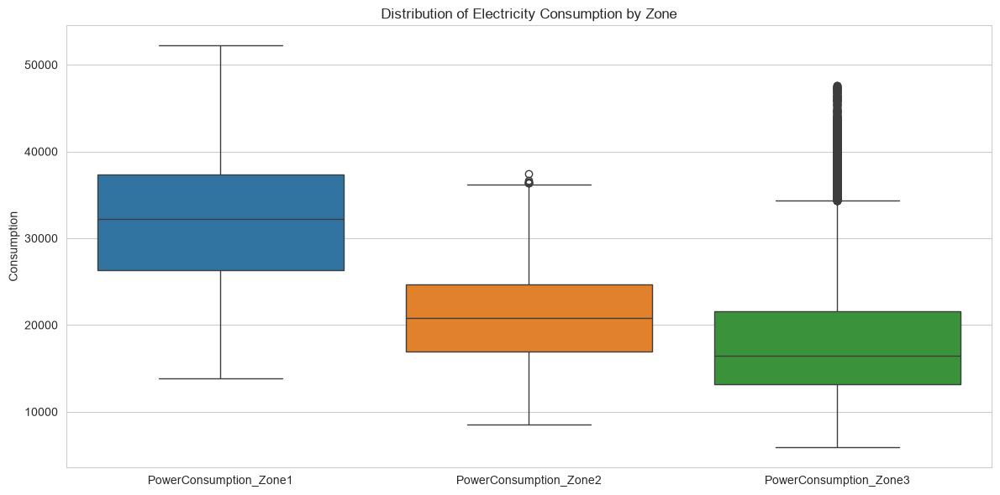

In [235]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[
        [
            'PowerConsumption_Zone1',
            'PowerConsumption_Zone2',
            'PowerConsumption_Zone3'
        ]
    ]
)

plt.title('Distribution of Electricity Consumption by Zone')
plt.ylabel('Consumption')

plt.tight_layout()
plt.savefig(
    '../outputs/electricity_consumption_distribution_by_zone.png',
    dpi=300,
    bbox_inches='tight')

plt.show()

In [239]:
fig = px.box(
    df,
    y=[
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ],
    title='Distribution of Electricity Consumption by Zone'
)

fig.update_layout(
    template='plotly_white',
    width=800,
    height=500,
    title_x=0.5,
    yaxis_title='Electricity Consumption'
)

fig.show()

### Average Consumption by Zone

In [123]:
zone_avg = df[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
].mean()
zone_avg

PowerConsumption_Zone1    32344.970564
PowerConsumption_Zone2    21042.509082
PowerConsumption_Zone3    17835.406218
dtype: float64

C:\Users\totes\AppData\Local\Temp\ipykernel_5100\1570756079.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


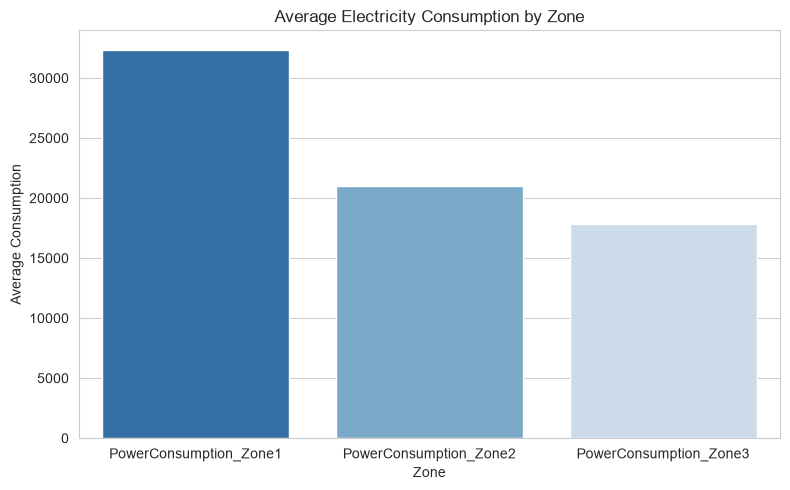

In [220]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=zone_avg.index,
    y=zone_avg.values,
    palette='Blues_r'
)

plt.title('Average Electricity Consumption by Zone')
plt.xlabel('Zone')
plt.ylabel('Average Consumption')

plt.tight_layout()

plt.savefig(
    '../outputs/average_consumption_by_zone.png',
    dpi=300,
    bbox_inches='tight')
plt.show()

Zone 1 recorded the highest average electricity consumption, while Zone 3 recorded the lowest average consumption.

In [221]:
zone_avg_df = zone_avg.reset_index()
zone_avg_df.columns = ['Zone', 'Average Consumption']

fig = px.bar(
    zone_avg_df,
    x='Zone',
    y='Average Consumption',
    color='Zone',
    title='Average Electricity Consumption by Zone',
    text_auto='.2f'
)

fig.update_layout(
    template='plotly_white',
    width=700,
    height=500,
    title_x=0.5
)


fig.show()

### Min and Max Consumption by Zone

In [125]:
df[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
].agg(['min', 'max', 'mean'])

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
min,13895.696200,8560.081466,5935.174070
max,52204.395120,37408.860760,47598.326360
mean,32344.970564,21042.509082,17835.406218


### Highest and Lowest Consumption Periods

In [126]:
df.loc[
    df['PowerConsumption_Zone1'].idxmax(),
    ['Datetime', 'PowerConsumption_Zone1']
]

Datetime                  2017-08-07 20:20:00
PowerConsumption_Zone1            52204.39512
Name: 31514, dtype: object

In [127]:
df.loc[
    df['PowerConsumption_Zone1'].idxmin(),
    ['Datetime', 'PowerConsumption_Zone1']
]

Datetime                  2017-01-15 07:30:00
PowerConsumption_Zone1             13895.6962
Name: 2061, dtype: object

Zone 1's peak consumption period was 07 August 2017 at 8.20 pm with a consumption reading of 52,204.40 KWh. Lowest consumption period was 15 January 2017 at 7.30 am with a reading of 13,895.70 KWh.

In [128]:
df.loc[
    df['PowerConsumption_Zone2'].idxmax(),
    ['Datetime', 'PowerConsumption_Zone2']
]

Datetime                  2017-07-24 19:40:00
PowerConsumption_Zone2            37408.86076
Name: 29494, dtype: object

In [129]:
df.loc[
    df['PowerConsumption_Zone2'].idxmin(),
    ['Datetime', 'PowerConsumption_Zone2']
]

Datetime                  2017-04-02 06:10:00
PowerConsumption_Zone2            8560.081466
Name: 13141, dtype: object

Zone 2's peak consumption period was 24 July 2017 at 7.40 pm with a consumption reading of 37,408.86 KWh. Lowest consumption period was 02 April 2017 at 6.10 am with a reading of 8,560.08 KWh.

In [130]:
df.loc[
    df['PowerConsumption_Zone3'].idxmax(),
    ['Datetime', 'PowerConsumption_Zone3']
]

Datetime                  2017-07-24 20:10:00
PowerConsumption_Zone3            47598.32636
Name: 29497, dtype: object

In [131]:
df.loc[
    df['PowerConsumption_Zone3'].idxmin(),
    ['Datetime', 'PowerConsumption_Zone3']
]

Datetime                  2017-12-11 07:00:00
PowerConsumption_Zone3             5935.17407
Name: 49578, dtype: object

Zone 3's peak consumption period was 24 July 2017 at 8.10 pm with a consumption reading of 47,598.33 KWh. Lowest consumption period was  11 December 2017 at 7.00 am with a reading of 5.935.18 KWh.

### Hourly Electricity Consumption Patterns

In [132]:
hourly = df.groupby('Hour')[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
].mean()

hourly.head()

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.235372,19692.073550,18657.222811
1,27565.533030,17765.078949,16970.804696
2,26292.688917,16730.156092,15981.096176
3,25338.122851,16052.585288,15238.605002
4,24633.576717,15624.081077,14671.039080


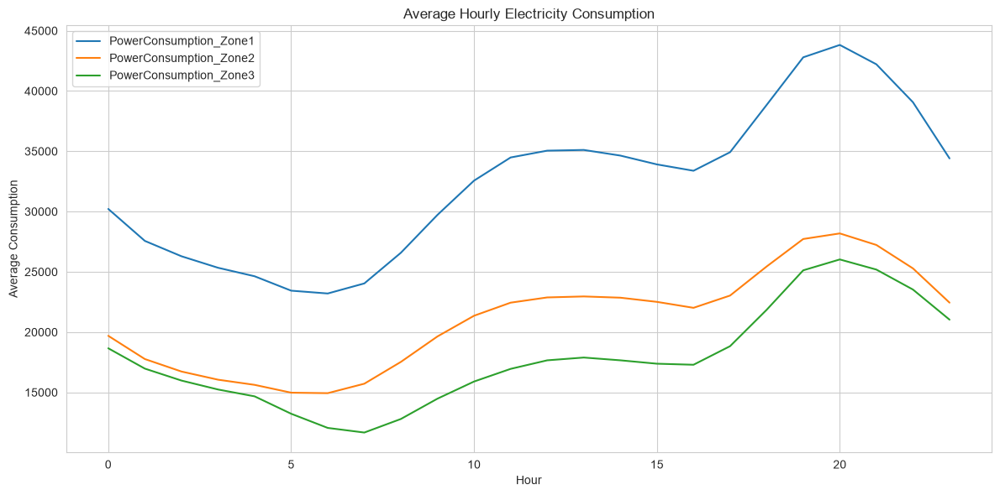

In [133]:
plt.figure(figsize=(12,6))

for col in hourly.columns:
    plt.plot(hourly.index, hourly[col], label=col)

plt.title('Average Hourly Electricity Consumption')
plt.xlabel('Hour')
plt.ylabel('Average Consumption')
plt.legend()

plt.tight_layout()

plt.savefig(
    '../outputs/average_hourly_consumption.png',
    dpi=300,
    bbox_inches='tight')
    
plt.show()

In [215]:
fig = px.line(
    hourly.reset_index(),
    x='Hour',
    y=[
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ],
    title='Hourly Electricity Consumption Patterns'
)

fig.update_layout(
    legend=dict(
        orientation='h',
        y=1.1,
        x=0.5,
        xanchor='center'
    )
)
fig.update_layout(
    template='plotly_white',
    width=700,
    height=500,
    title_x=0.5
)
fig.show()

In [134]:
hourly.idxmax()

PowerConsumption_Zone1    20
PowerConsumption_Zone2    20
PowerConsumption_Zone3    20
dtype: int32

In [135]:
hourly.idxmin()

PowerConsumption_Zone1    6
PowerConsumption_Zone2    6
PowerConsumption_Zone3    7
dtype: int32

In [150]:
hourly.round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.24,19692.07,18657.22
1,27565.53,17765.08,16970.80
2,26292.69,16730.16,15981.10
3,25338.12,16052.59,15238.61
4,24633.58,15624.08,14671.04
5,23437.58,14974.91,13226.38
6,23203.60,14934.70,12051.60
7,24038.35,15719.12,11667.86
8,26583.26,17529.68,12793.79


Zone 1, 2, and 3 recorded the highest hourly consumption readings at 8pm. Meanwhile the lowest readings, according to the chart, were recorded at 6am by zone 1 and 2, and at 7am for zone 3.

### Weekly Consumption Patterns

In [136]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

In [151]:
weekly = df.groupby('Day_of_Week')[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
].mean()

weekly = weekly.reindex(day_order)

weekly.round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day_of_Week,,,
Monday,32615.41,21280.07,17809.08
Tuesday,32713.03,21518.60,17831.69
Wednesday,32871.76,21627.36,17851.40
Thursday,32842.48,21845.16,17843.69
Friday,32339.00,21461.04,17545.97
Saturday,32253.03,20585.96,18011.19
Sunday,30780.08,18979.38,17954.83


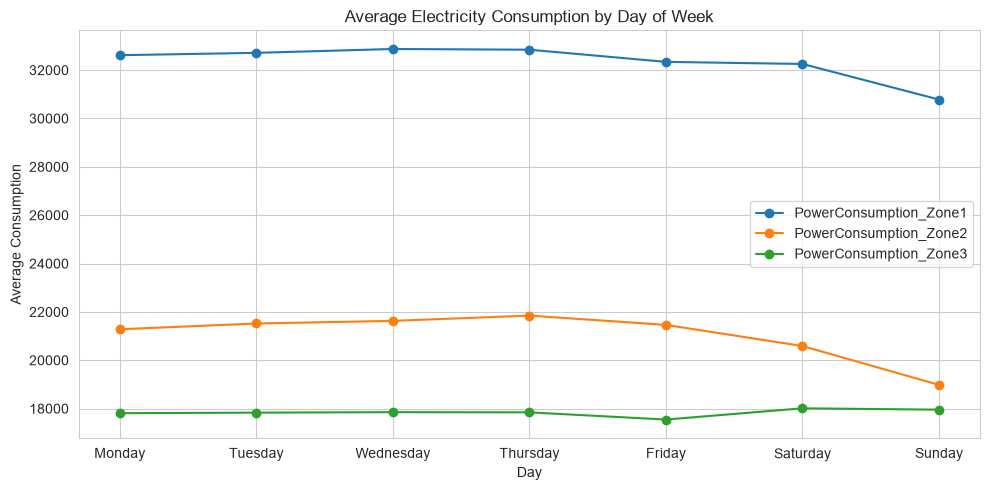

In [164]:
weekly.plot(
    figsize=(10,5),
    marker='o'
)

plt.title('Average Electricity Consumption by Day of Week')
plt.xlabel('Day')
plt.ylabel('Average Consumption')

plt.tight_layout()

plt.savefig(
    '../outputs/average_daily_consumption.png',
    dpi=300,
    bbox_inches='tight')

plt.show()

In [139]:
weekly.idxmax()

PowerConsumption_Zone1    Wednesday
PowerConsumption_Zone2     Thursday
PowerConsumption_Zone3     Saturday
dtype: str

In [140]:
weekly.idxmin()

PowerConsumption_Zone1    Sunday
PowerConsumption_Zone2    Sunday
PowerConsumption_Zone3    Friday
dtype: str

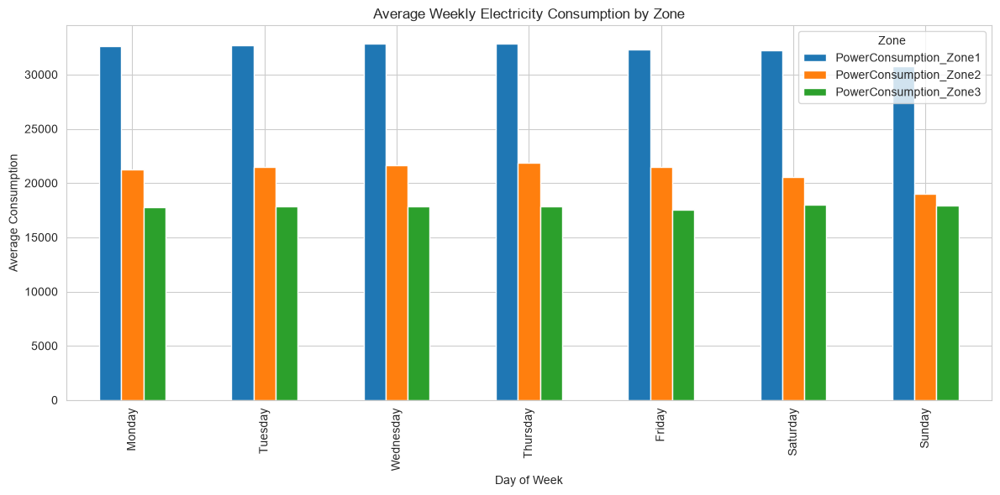

In [141]:
weekly.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Average Weekly Electricity Consumption by Zone')
plt.xlabel('Day of Week')
plt.ylabel('Average Consumption')

plt.legend(title='Zone')

plt.tight_layout()

plt.savefig(
    '../outputs/bar_average_daily_consumption.png',
    dpi=300,
    bbox_inches='tight')
plt.show()


In [223]:
weekly_plot = weekly.reset_index()

fig = px.bar(
    weekly_plot,
    x='Day_of_Week',
    y=[
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ],
    barmode='group',
    title='Average Weekly Electricity Consumption by Zone'
)

fig.update_layout(
    template='plotly_white',
    width=800,
    height=500,
    title_x=0.5,
    xaxis_title='Day of Week',
    yaxis_title='Average Consumption'
)

fig.show()

- Zone 1 recorded it's highest consumption readings on Wednesday and lowest on Sunday.
- Zone 2 recorded its highest consumption readings on Thursday and lowest on Sunday.
- Zone 3 recorded its highest readings on Saturday and lowest on Friday.

### Monthly Consumption Patterns

In [142]:
monthly = df.groupby('Month_Name')[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
].mean()

In [152]:
month_order = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December'
]

monthly = monthly.reindex(month_order)
monthly.round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month_Name,,,
January,31032.49,19394.44,17746.10
February,30985.75,18787.79,17335.00
March,31155.17,18457.94,16947.69
April,31169.77,17633.97,18593.17
May,32396.01,19977.29,17621.10
June,34605.54,20670.93,20430.94
July,35831.55,24147.89,28194.11
August,36435.19,24656.22,24648.89
September,33396.68,20180.43,14922.80


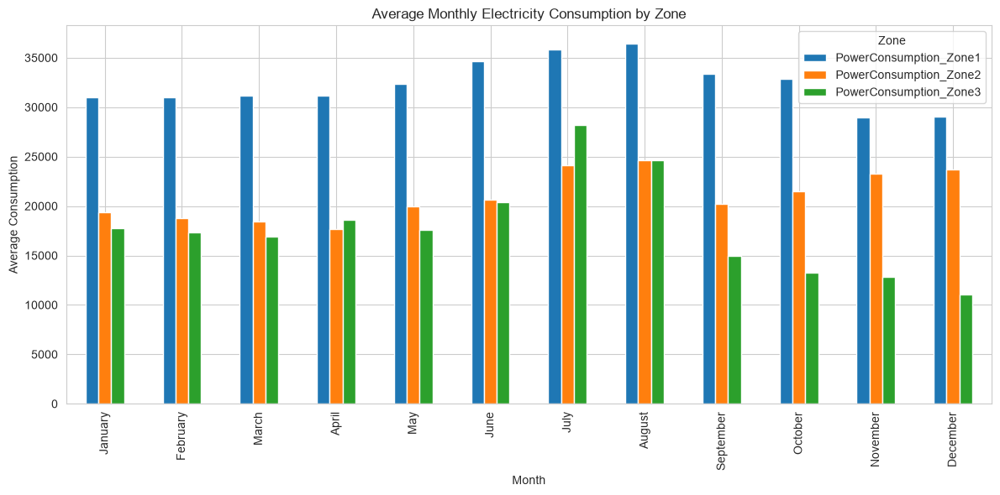

In [154]:
monthly.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Average Monthly Electricity Consumption by Zone')
plt.xlabel('Month')
plt.ylabel('Average Consumption')

plt.legend(title='Zone')

plt.tight_layout()

plt.savefig(
    '../outputs/bar_average_monthly_consumption.png',
    dpi=300,
    bbox_inches='tight')

plt.show()


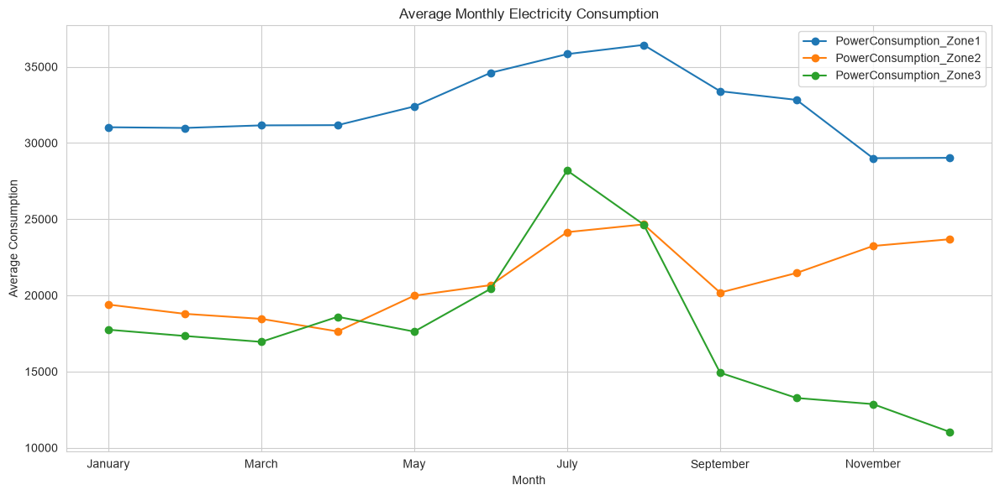

In [163]:
monthly.plot(
    figsize=(12,6),
    marker='o'
)

plt.title('Average Monthly Electricity Consumption')
plt.xlabel('Month')
plt.ylabel('Average Consumption')

plt.tight_layout()

plt.savefig(
    '../outputs/average_monthly_consumption.png',
    dpi=300,
    bbox_inches='tight')

plt.show()

In [224]:
monthly_plot = monthly.reset_index()

fig = px.line(
    monthly_plot,
    x='Month_Name',
    y=[
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ],
    markers=True,
    title='Monthly Electricity Consumption Patterns'
)

fig.update_layout(
    template='plotly_white',
    width=950,
    height=500,
    title_x=0.5,
    xaxis_title='Month',
    yaxis_title='Average Consumption'
)

fig.show()

In [146]:
monthly.idxmax()

PowerConsumption_Zone1    August
PowerConsumption_Zone2    August
PowerConsumption_Zone3      July
dtype: str

In [94]:
monthly.idxmin()

PowerConsumption_Zone1    November
PowerConsumption_Zone2       April
PowerConsumption_Zone3    December
dtype: str

- The highest consumption readings were recorded in August for Zone 1 and 2, and July for Zone 3.
- The lowest electricity consumption readings were recorded in November for Zone 1, April for Zone 2, and December for Zone 3.

### Overall Electricity Consumption Trend

In [159]:
daily = df.groupby('Date')[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
].mean()
daily.round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Date,,,
2017-01-01,28465.23,17737.79,17868.80
2017-01-02,28869.49,19557.73,17820.76
2017-01-03,30562.45,20057.27,17620.80
2017-01-04,30689.83,20102.08,17673.69
2017-01-05,30802.91,20033.94,17664.18
...,...,...,...
2017-12-26,30013.48,24757.01,11395.68
2017-12-27,29966.96,25057.48,11498.28
2017-12-28,30267.00,24585.25,11167.03


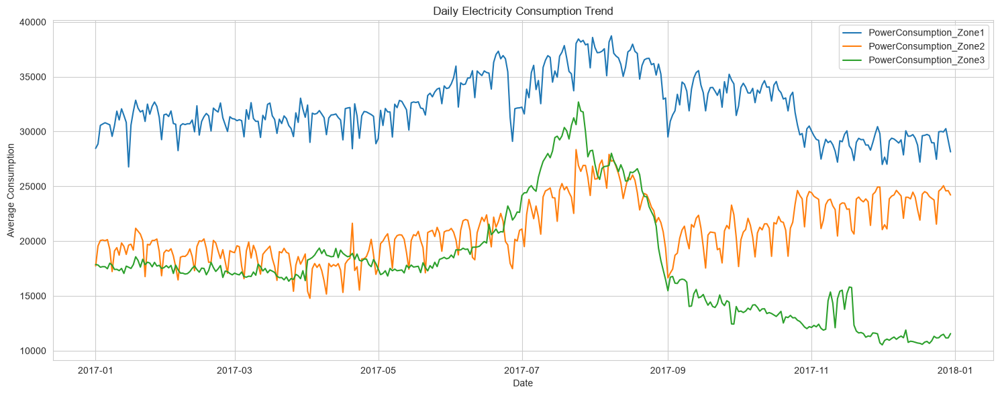

In [165]:
plt.figure(figsize=(15,6))

for col in daily.columns:
    plt.plot(daily.index, daily[col], label=col)

plt.title('Daily Electricity Consumption Trend')
plt.xlabel('Date')
plt.ylabel('Average Consumption')

plt.legend()

plt.tight_layout()

plt.savefig(
    '../outputs/overall_average_consumption.png',
    dpi=300,
    bbox_inches='tight')

plt.show()

In [166]:
daily.idxmax()

PowerConsumption_Zone1    2017-08-08
PowerConsumption_Zone2    2017-07-24
PowerConsumption_Zone3    2017-07-25
dtype: object

In [168]:
daily.max()

PowerConsumption_Zone1    38733.496116
PowerConsumption_Zone2    28354.535865
PowerConsumption_Zone3    32700.209205
dtype: float64

In [167]:
daily.idxmin()

PowerConsumption_Zone1    2017-01-15
PowerConsumption_Zone2    2017-04-02
PowerConsumption_Zone3    2017-12-01
dtype: object

In [169]:
daily.min()

PowerConsumption_Zone1    26771.518987
PowerConsumption_Zone2    14779.098778
PowerConsumption_Zone3    10530.612245
dtype: float64

Peak electricity consumption readings were recorded in August 2017 for all three zones. Zone 1 recorded the highest overall consumption in comparison to the other zones. Overall electricity consumption was relatively stable over time. Consumption peaked between July and August in all three zones. Consumption in zone 3 spiked in between July and August but continued declining more than zone 2 until november when it spiked for a short time and sharply declined again.

## Task 4: Environmental Factor Relationship Analysis
Investigating the relationship between electricity consumption and environmental factors, such as temperature, humidity, and wind speed.

In [172]:
corr_cols = [
    'Temperature',
    'Humidity',
    'WindSpeed',
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

corr_matrix = df[corr_cols].corr()

corr_matrix.round(2)

,Temperature,Humidity,WindSpeed,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,1.00,-0.46,0.48,0.44,0.38,0.49
Humidity,-0.46,1.00,-0.14,-0.29,-0.29,-0.23
WindSpeed,0.48,-0.14,1.00,0.17,0.15,0.28
PowerConsumption_Zone1,0.44,-0.29,0.17,1.00,0.83,0.75
PowerConsumption_Zone2,0.38,-0.29,0.15,0.83,1.00,0.57
PowerConsumption_Zone3,0.49,-0.23,0.28,0.75,0.57,1.00


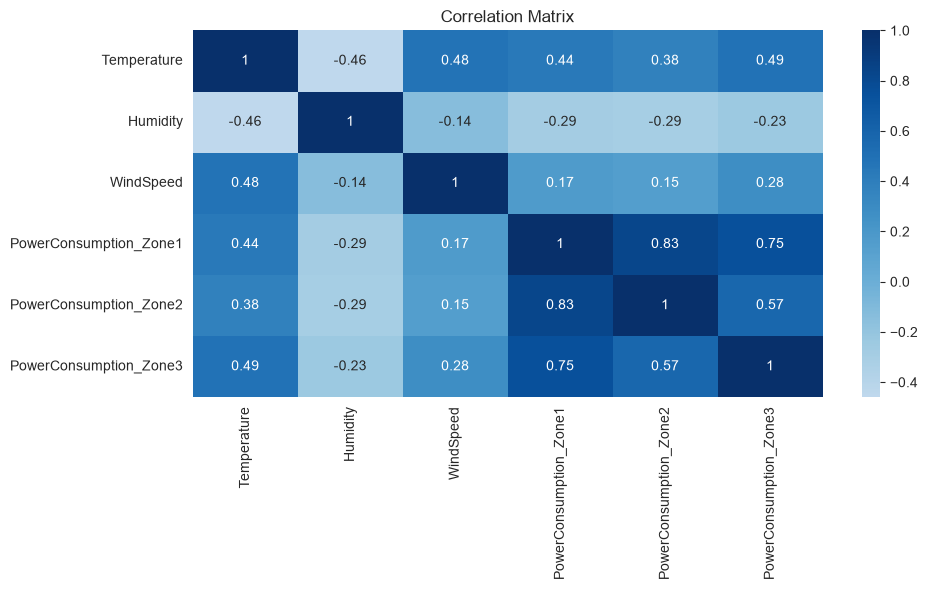

In [184]:
plt.figure(figsize=(10,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='Blues',
    center=0
)

plt.title('Correlation Matrix')

plt.tight_layout()

plt.savefig(
    '../outputs/correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Zone 1 and 3's electricity consumption have a moderate positive correlation with Temperature, suggesting that electricity consumption in the 2 zones may be slightly related to temperature. Zone 2 shows weaker correlation with temperature than Zones 1 and 3. All three zones have negative correlation with humidity, indicating that humidity may not be associated with electricity consumption. All three zones show weak correlation with windspeed. This indicates that humidity and wind speed do not affect electricity consumption, but temperature may have a slight impact on consumption. Notably, correlation does not imply causation. Further investigation is required to determine is temperature truely has an impact on electricity consumption.

### Temperature vs Consumption

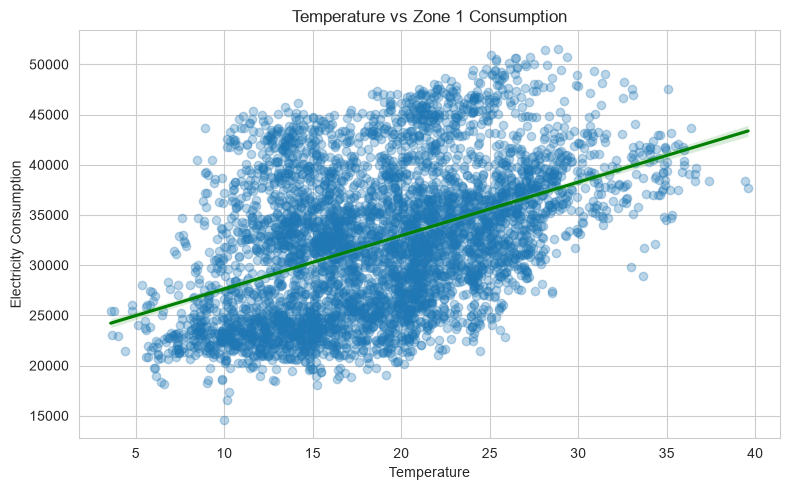

In [197]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df.sample(5000, random_state=42),
    x='Temperature',
    y='PowerConsumption_Zone1',
    scatter_kws={'alpha':0.3},
    line_kws={'color':'green'}
)

plt.title('Temperature vs Zone 1 Consumption')
plt.xlabel('Temperature')
plt.ylabel('Electricity Consumption')

plt.tight_layout()

plt.savefig(
    '../outputs/zone1_temp_vs_consumption.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

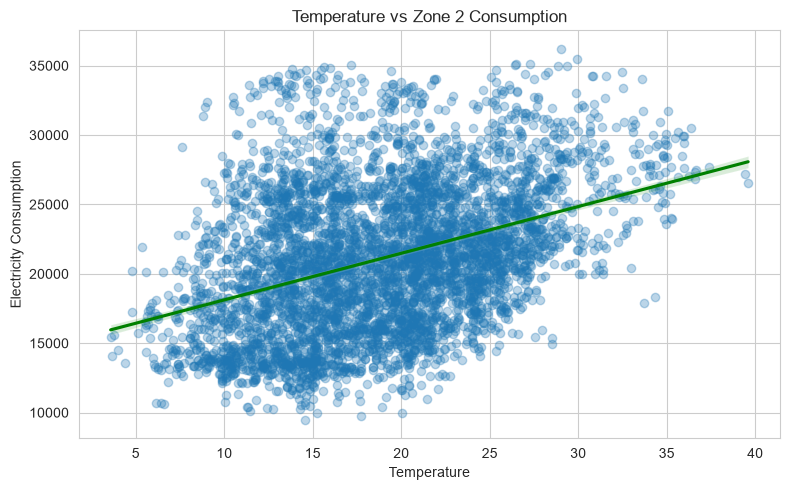

In [199]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df.sample(5000, random_state=42),
    x='Temperature',
    y='PowerConsumption_Zone2',
    scatter_kws={'alpha':0.3},
    line_kws={'color':'green'}
)

plt.title('Temperature vs Zone 2 Consumption')
plt.xlabel('Temperature')
plt.ylabel('Electricity Consumption')

plt.tight_layout()

plt.savefig(
    '../outputs/zone2_temp_vs_consumption.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

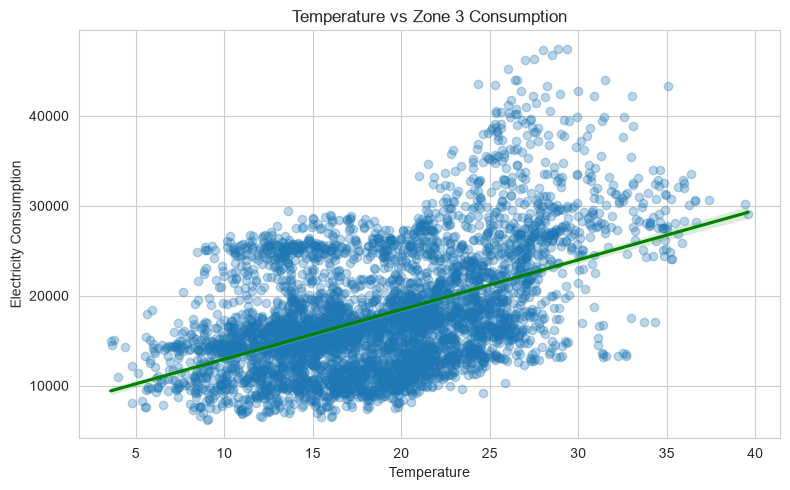

In [200]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df.sample(5000, random_state=42),
    x='Temperature',
    y='PowerConsumption_Zone3',
    scatter_kws={'alpha':0.3},
    line_kws={'color':'green'}
)

plt.title('Temperature vs Zone 3 Consumption')
plt.xlabel('Temperature')
plt.ylabel('Electricity Consumption')

plt.tight_layout()

plt.savefig(
    '../outputs/zone3_temp_vs_consumption.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Humidity vs Consumption

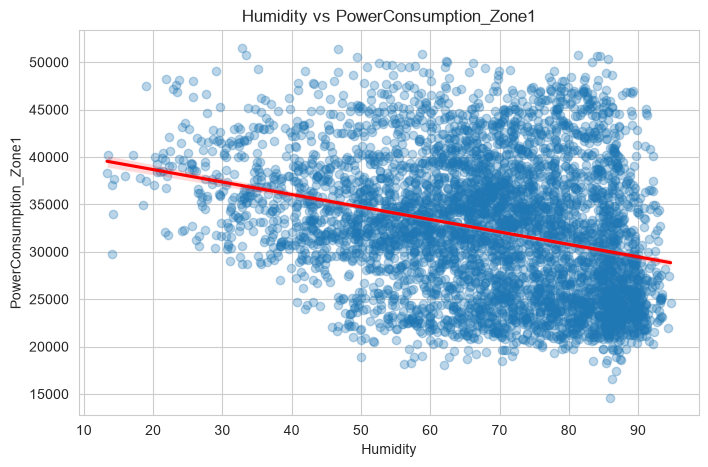

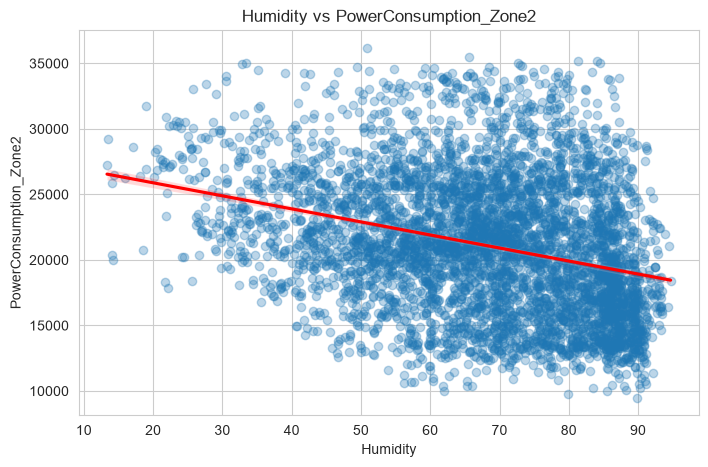

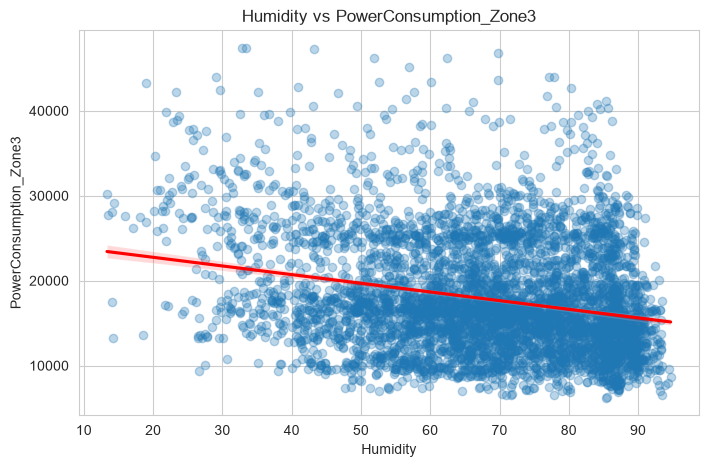

In [203]:
for zone in zones:

    plt.figure(figsize=(8,5))
    
    sns.regplot(
        data=df.sample(5000, random_state=42),
        x='Humidity',
        y=zone,
        scatter_kws={'alpha':0.3},
        line_kws={'color':'red'}
    )
    
    plt.title(f'Humidity vs {zone}')
    
    plt.show()

### Windspeed vs Consumption

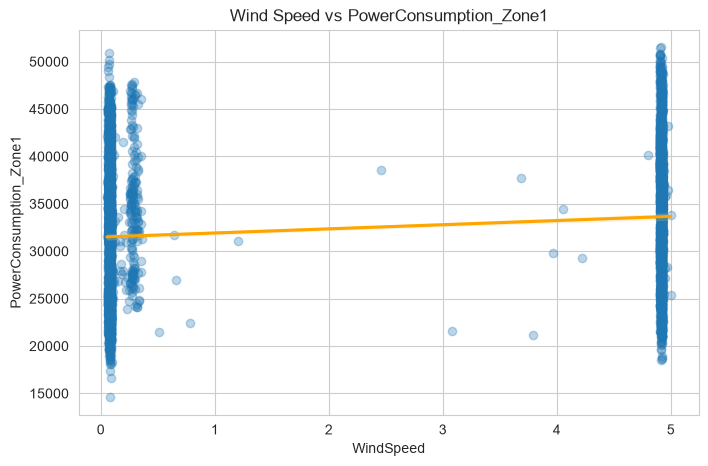

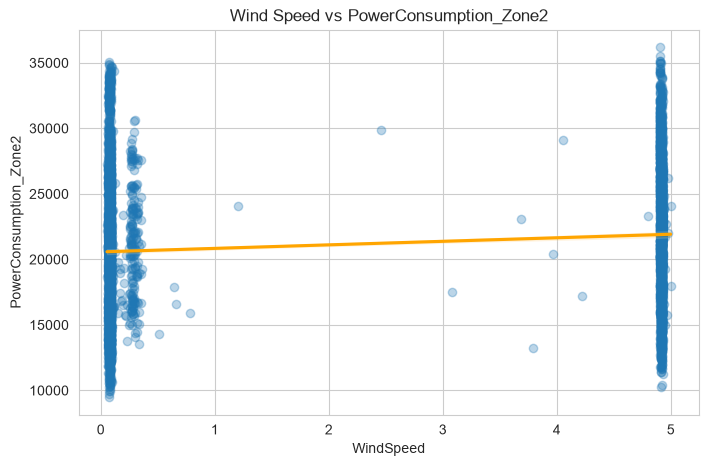

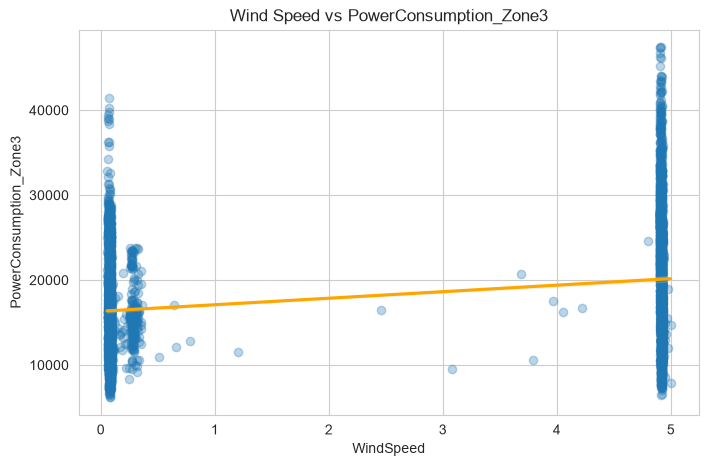

In [204]:
for zone in zones:

    plt.figure(figsize=(8,5))
    
    sns.regplot(
        data=df.sample(5000, random_state=42),
        x='WindSpeed',
        y=zone,
        scatter_kws={'alpha':0.3},
        line_kws={'color':'orange'}
    )
    
    plt.title(f'Wind Speed vs {zone}')
    
    plt.show()


In [206]:
environmental_summary = pd.DataFrame({
    'Zone1': [
        df['Temperature'].corr(df['PowerConsumption_Zone1']),
        df['Humidity'].corr(df['PowerConsumption_Zone1']),
        df['WindSpeed'].corr(df['PowerConsumption_Zone1'])
    ],
    'Zone2': [
        df['Temperature'].corr(df['PowerConsumption_Zone2']),
        df['Humidity'].corr(df['PowerConsumption_Zone2']),
        df['WindSpeed'].corr(df['PowerConsumption_Zone2'])
    ],
    'Zone3': [
        df['Temperature'].corr(df['PowerConsumption_Zone3']),
        df['Humidity'].corr(df['PowerConsumption_Zone3']),
        df['WindSpeed'].corr(df['PowerConsumption_Zone3'])
    ]
},
index=['Temperature', 'Humidity', 'Wind Speed'])

environmental_summary.round(2)

,Zone1,Zone2,Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
Wind Speed,0.17,0.15,0.28


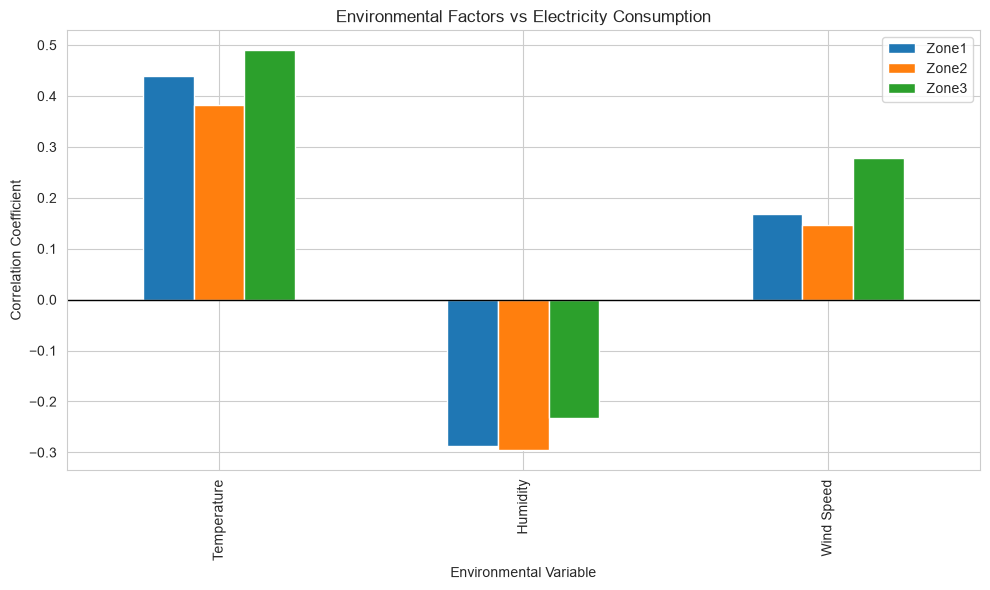

In [207]:
environmental_summary.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Environmental Factors vs Electricity Consumption')
plt.xlabel('Environmental Variable')
plt.ylabel('Correlation Coefficient')

plt.axhline(0, color='black', linewidth=1)

plt.tight_layout()

plt.show()

In [226]:
env_plot = environmental_summary.reset_index()
env_plot.rename(columns={'index':'Environmental Factor'}, inplace=True)

fig = px.bar(
    env_plot,
    x='Environmental Factor',
    y=['Zone1', 'Zone2', 'Zone3'],
    barmode='group',
    title='Environmental Factors and Electricity Consumption Correlations'
)

fig.update_layout(
    template='plotly_white',
    width=800,
    height=500,
    title_x=0.5,
    yaxis_title='Correlation Coefficient'
)

fig.show()

C:\Users\totes\AppData\Local\Temp\ipykernel_5100\3197861222.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  env_plot.rename(columns={'index':'Environmental Factor'}, inplace=True)


1. Temperature shows a moderate positive relationship with electricity consumption across all zones.

2. Humidity exhibits a weak negative relationship with electricity consumption.

3. Wind speed demonstrates little to no relationship with electricity demand.

4. Environmental variables influence electricity consumption differently across the three zones.

5. Temperature appears to be the strongest environmental predictor of electricity consumption among the variables investigated.
